# 02. Воронка заказа

Сколько заказов доходит от создания до доставки, где теряются и сколько времени занимает каждый этап.

Этапы: `создан -> оплачен -> отгружен -> доставлен`; отмена возможна до оплаты (не оплатили) и после неё (до отгрузки).

**Данные:** `marts.fct_orders`. Время этапов (`paid_at`, `shipped_at`, ...) восстановлено из журнала CDC `shop.orders_changelog`, поэтому в воронке есть и заказы, которые в Postgres уже удалены.

In [1]:
import sys
sys.path.insert(0, "..")  # модуль analytics лежит в корне репозитория

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from analytics.db import query
from analytics.plots import setup, money_axis, percent_axis, BLUE, ORANGE, AQUA, YELLOW, GRAY, SERIES

setup()
pd.set_option("display.float_format", "{:,.2f}".format)

from scipy import stats
from statsmodels.stats.proportion import proportion_confint

In [2]:
orders = query("""
    select order_id, customer_id, status, is_deleted, created_at,
           paid_at, shipped_at, delivered_at, cancelled_at,
           hours_to_paid, hours_paid_to_shipped, hours_shipped_to_delivered,
           customer_order_number
    from fct_orders
""")
data_end = orders.created_at.max()
orders["age_days"] = (data_end - orders.created_at).dt.total_seconds() / 86400
orders["is_final"] = orders.delivered_at.notna() | orders.cancelled_at.notna()
print(f"{len(orders):,} заказов, данные до {data_end:%d.%m.%Y %H:%M} UTC; удалённых в источнике: {orders.is_deleted.sum()}")

16,430 заказов, данные до 29.10.2026 10:48 UTC; удалённых в источнике: 0


## Правое цензурирование

Заказ, созданный вчера, ещё не успел дойти до доставки. Если посчитать воронку по всем заказам, конверсия в доставку будет занижена - не потому что заказы теряются, а потому что их история не закончилась. Поэтому сначала находим возраст, после которого заказ почти наверняка в финальном статусе (доставлен или отменён), и строим воронку только по «созревшим» заказам.

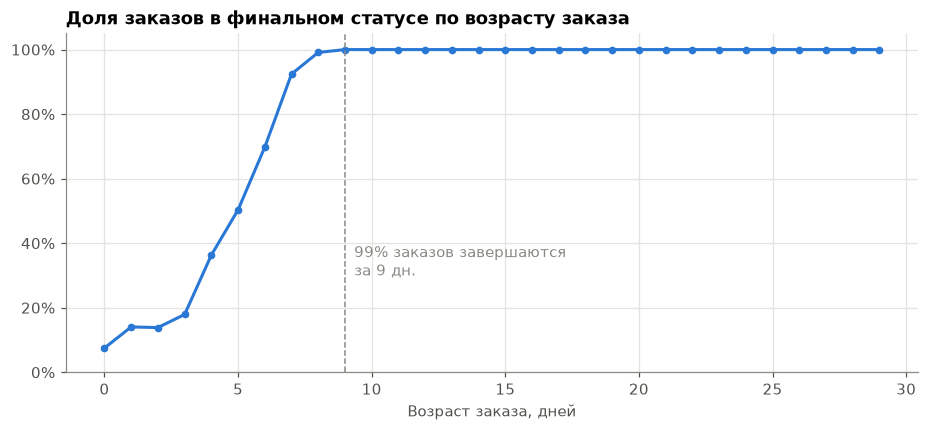

Созревших заказов: 15,203 из 16,430


In [3]:
done = orders[orders.is_final]
final_at = done.delivered_at.fillna(done.cancelled_at)
days_to_final = (final_at - done.created_at).dt.total_seconds() / 86400
maturity_days = int(np.ceil(days_to_final.quantile(0.99)))

young = orders[orders.age_days < 30]
by_age = young.groupby(young.age_days.astype(int)).is_final.mean()

fig, ax = plt.subplots()
ax.plot(by_age.index, by_age.values, color=BLUE, marker="o", markersize=4)
ax.axvline(maturity_days, color=GRAY, linestyle="--", linewidth=1)
ax.annotate(f"99% заказов завершаются\nза {maturity_days} дн.", (maturity_days, 0.3), xytext=(6, 0),
            textcoords="offset points", color=GRAY)
percent_axis(ax)
ax.set_ylim(0, 1.05)
ax.set_title("Доля заказов в финальном статусе по возрасту заказа")
ax.set_xlabel("Возраст заказа, дней")
plt.show()

matured = orders[orders.age_days >= maturity_days]
print(f"Созревших заказов: {len(matured):,} из {len(orders):,}")

In [4]:
def funnel_table(df):
    created = len(df)
    steps = pd.Series({
        "Создан": created,
        "Оплачен": df.paid_at.notna().sum(),
        "Отгружен": df.shipped_at.notna().sum(),
        "Доставлен": df.delivered_at.notna().sum(),
    })
    return pd.DataFrame({
        "Заказов": steps,
        "От созданных": steps / created,
        "От предыдущего этапа": steps / steps.shift(1),
    })

compare = pd.DataFrame({
    "Все заказы": funnel_table(orders)["От созданных"],
    "Только созревшие": funnel_table(matured)["От созданных"],
})
compare.style.format("{:.1%}")

,Все заказы,Только созревшие
Создан,100.0%,100.0%
Оплачен,88.9%,88.9%
Отгружен,84.4%,85.4%
Доставлен,81.3%,85.4%


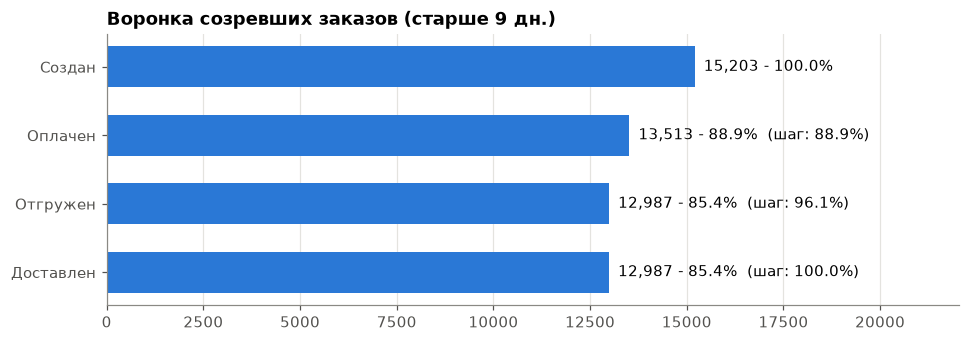

,Заказов,От созданных,От предыдущего этапа
Создан,"15,203",100.0%,-
Оплачен,"13,513",88.9%,88.9%
Отгружен,"12,987",85.4%,96.1%
Доставлен,"12,987",85.4%,100.0%


In [5]:
funnel = funnel_table(matured)

fig, ax = plt.subplots(figsize=(10, 3.2))
ax.barh(funnel.index[::-1], funnel["Заказов"][::-1], color=BLUE, height=0.6)
for i, (name, row) in enumerate(funnel[::-1].iterrows()):
    step = "" if name == "Создан" else f"  (шаг: {row['От предыдущего этапа']:.1%})"
    ax.annotate(f"{row['Заказов']:,.0f} - {row['От созданных']:.1%}{step}", (row["Заказов"], i),
                xytext=(6, 0), textcoords="offset points", va="center")
ax.set_xlim(0, funnel["Заказов"].max() * 1.45)
ax.set_title(f"Воронка созревших заказов (старше {maturity_days} дн.)")
ax.grid(axis="y", visible=False)
plt.show()
funnel.style.format({"Заказов": "{:,.0f}", "От созданных": "{:.1%}", "От предыдущего этапа": "{:.1%}"}, na_rep="-")

## Где отменяют

Отмена до оплаты - клиент передумал или не смог заплатить; после оплаты - магазин потерял уже оплаченный заказ (возврат денег), это дороже.

In [6]:
cancelled = matured[matured.cancelled_at.notna()]
where = pd.Series({
    "До оплаты": cancelled.paid_at.isna().sum(),
    "После оплаты, до отгрузки": cancelled.paid_at.notna().sum(),
})
pd.DataFrame({"Отмен": where, "Доля созревших заказов": where / len(matured), "Доля отмен": where / where.sum()}) \
    .style.format({"Отмен": "{:,.0f}", "Доля созревших заказов": "{:.1%}", "Доля отмен": "{:.1%}"})

,Отмен,Доля созревших заказов,Доля отмен
До оплаты,"1,690",11.1%,76.3%
"После оплаты, до отгрузки",526,3.5%,23.7%


## Время между этапами

Медиана и 90-й перцентиль: среднее здесь плохо описывает «обычный» заказ из-за длинных хвостов ожидания оплаты.

,Заказов,Медиана,P90,Максимум
"Создан -> оплачен, ч","13,513",2.0,7.0,31.2
"Оплачен -> отгружен, ч","12,987",41.8,66.0,72.0
"Отгружен -> доставлен, ч","12,987",96.0,134.6,144.0


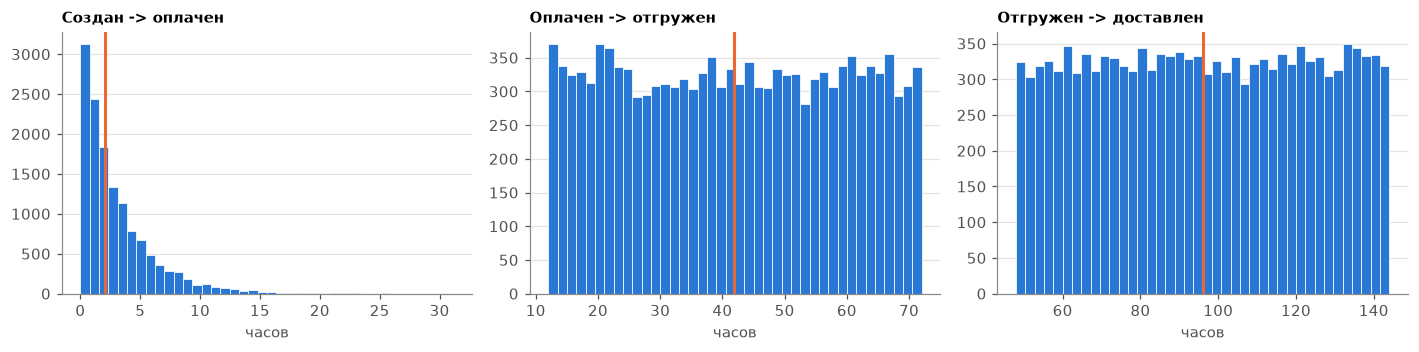

In [7]:
durations = pd.DataFrame({
    "Создан -> оплачен, ч": matured.hours_to_paid,
    "Оплачен -> отгружен, ч": matured.hours_paid_to_shipped,
    "Отгружен -> доставлен, ч": matured.hours_shipped_to_delivered,
})
summary = durations.describe(percentiles=[0.5, 0.9]).T[["count", "50%", "90%", "max"]]
summary.columns = ["Заказов", "Медиана", "P90", "Максимум"]
display(summary.style.format({"Заказов": "{:,.0f}", "Медиана": "{:.1f}", "P90": "{:.1f}", "Максимум": "{:.1f}"}))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.3))
for ax, col in zip(axes, durations.columns):
    values = durations[col].dropna()
    ax.hist(values, bins=40, color=BLUE, edgecolor="white", linewidth=0.5)
    ax.axvline(values.median(), color=ORANGE, linewidth=2)
    ax.set_title(col.replace(", ч", ""), fontsize=10)
    ax.set_xlabel("часов")
    ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

## Доля отмен по неделям

Только созревшие заказы, 95% доверительный интервал Уилсона: при ~600 заказах в неделю случайный разброс доли отмен - около ±3 п.п., и колебания внутри этого коридора не стоит интерпретировать как тренд.

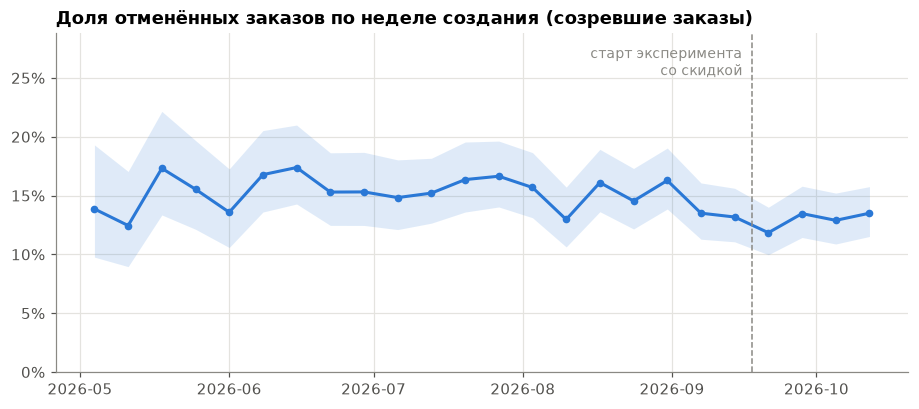

In [8]:
weekly = (matured.assign(week=matured.created_at.dt.tz_localize(None).dt.to_period("W-SUN").dt.start_time,
                         cancelled=matured.cancelled_at.notna())
          .groupby("week").agg(orders=("order_id", "size"), cancelled=("cancelled", "sum")))
# только недели, целиком попавшие в "созревший" период: у последней недели созрели бы 1-2 дня,
# и её доля считалась бы по нерепрезентативной выборке
last_full_week = (data_end - pd.Timedelta(days=maturity_days)).tz_localize(None) - pd.Timedelta(days=7)
weekly = weekly[(weekly.index <= last_full_week) & (weekly.orders >= 100)]  # первая неделя тоже неполная
experiment_start = query("select min(window_start) as ts from mart_ab_users").ts[0]
weekly["rate"] = weekly.cancelled / weekly.orders
weekly["lo"], weekly["hi"] = proportion_confint(weekly.cancelled, weekly.orders, method="wilson")

fig, ax = plt.subplots()
ax.fill_between(weekly.index, weekly.lo, weekly.hi, color=BLUE, alpha=0.15, linewidth=0)
ax.plot(weekly.index, weekly.rate, color=BLUE, marker="o", markersize=4)
percent_axis(ax)
ax.set_ylim(0, weekly.hi.max() * 1.3)
ax.axvline(experiment_start, color=GRAY, linestyle="--", linewidth=1)
ax.annotate("старт эксперимента\nсо скидкой", (experiment_start, weekly.hi.max() * 1.25), xytext=(-6, 0),
            textcoords="offset points", ha="right", va="top", color=GRAY, fontsize=9)
ax.set_title("Доля отменённых заказов по неделе создания (созревшие заказы)")
plt.show()

## Первый заказ клиента и повторные

Отличается ли доля оплаты у первого заказа клиента и у повторных? Проверяем хи-квадрат тестом независимости (H0: доля оплаченных не зависит от того, первый это заказ или нет).

In [9]:
m = matured.assign(kind=np.where(matured.customer_order_number == 1, "Первый заказ", "Повторный"),
                   paid=matured.paid_at.notna())
table = pd.crosstab(m.kind, m.paid)
chi2, p_value, _, _ = stats.chi2_contingency(table)

rates = m.groupby("kind").paid.agg(["size", "sum", "mean"])
rates["lo"], rates["hi"] = proportion_confint(rates["sum"], rates["size"], method="wilson")
rates.columns = ["Заказов", "Оплачено", "Доля оплаты", "95% ДИ, от", "95% ДИ, до"]
display(rates.style.format({"Заказов": "{:,.0f}", "Оплачено": "{:,.0f}", "Доля оплаты": "{:.1%}",
                            "95% ДИ, от": "{:.1%}", "95% ДИ, до": "{:.1%}"}))
print(f"chi2 = {chi2:.2f}, p-value = {p_value:.3f}")

,Заказов,Оплачено,Доля оплаты,"95% ДИ, от","95% ДИ, до"
kind,,,,,
Первый заказ,"5,878","5,240",89.1%,88.3%,89.9%
Повторный,"9,325","8,273",88.7%,88.1%,89.3%


chi2 = 0.62, p-value = 0.429


## Выводы

*Данные синтетические (`backfill.py`, seed 42): цифры описывают модель магазина, а ценность ноутбука - в методике.*

1. **Воронка созревших заказов** (старше 9 дней, 15.2 тыс.): оплачено 88.9% -> отгружено 85.4% -> доставлено 85.4%. После отгрузки заказы не теряются - все потери происходят до отгрузки.
2. **Цензурирование важно.** Воронка по всем заказам занижает долю доставленных: 81.3% против 85.4%. Порог созревания (9 дней) взят как 99-й перцентиль времени до финального статуса, а не «на глаз».
3. **Главная потеря - неоплата:** 11.1% заказов отменяются до оплаты, это 76% всех отмен. Отмены после оплаты реже (3.5%), но дороже: деньги нужно вернуть, а заказ уже собран.
4. **Время этапов:** оплата - медиана 2.0 ч (P90 7 ч), до отгрузки - 41.8 ч (P90 66 ч), доставка - 96 ч (P90 135 ч). По времени узкое место - доставка, по деньгам - неоплаченные заказы.
5. **Первый заказ клиента оплачивают так же, как повторные:** 89.1% против 88.7%, p = 0.43 - различие не значимо. Работа над конверсией в оплату нужна для всех заказов, а не только для новичков.
6. **Доля отмен по неделям** колеблется в коридоре 12-17% и почти целиком помещается в доверительные интервалы соседних недель - устойчивого тренда нет. Снижение после старта эксперимента ожидаемо (со скидкой заказы чаще оплачивают), но его величину корректно оценивать сравнением групп, а не «до/после» (ноутбук 05).